# Prática 3 — Por onde começar a configurar o Random Forest?

**Continuação da Prática 2 · Regressão desbalanceada · Carlos Henrique**

Mantemos os 30 datasets, a avaliação por SERA e as meta-características da Prática 2.
Agora fixamos o Random Forest e perguntamos:

> **Começar por configurações boas em datasets parecidos ajuda a encontrar mais rapidamente uma boa configuração no dataset novo?**

Seguimos o problema estudado por Juscimara Avelino e colaboradores no Meta-IR.
Lá, o objetivo é recomendar regressor e reamostragem. Aqui, o regressor está escolhido;
queremos orientar o começo da busca de hiperparâmetros. Feurer et al. fornecem a ideia do warm-start.

Todo o código do experimento está neste notebook. Reaproveitamos dos arquivos anteriores
os dados, os descritores e as funções de SERA. **Experimento completo executado: matriz 60 × 30, buscas com vinte sementes e as três análises.**

## 1. O que precisamos entender

O caminho inteiro é:

**avaliar configurações → guardar as perdas → simular buscas → comparar os resultados.**

A parte cara é treinar os modelos para construir a tabela. Depois disso, cada busca
consulta a tabela, como se estivesse avaliando uma configuração naquele momento.

Random Forest é o **regressor base**, que prevê o alvo do dataset. Ele é um dos
regressores usados no Meta-IR e teve o melhor rank médio nos nossos resultados anteriores.
Não usamos aqui o meta-classificador do Meta-IR.

**Para explicar:** “Escolhi um regressor e vou investigar como encontrar uma boa configuração com poucas avaliações.”

In [1]:
from pathlib import Path
from itertools import product
import json
import sys
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.stats import norm, friedmanchisquare, spearmanr
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import KFold
from sklearn.preprocessing import StandardScaler
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import Matern

# Funciona abrindo o notebook nesta pasta ou na raiz do repositório.
candidatos = [Path.cwd(), Path.cwd().parent, Path.cwd() / 'projeto-01']
BASE = next(p.resolve() for p in candidatos if (p / 'meta-dataset' / 'X.csv').exists() and (p / 'data').is_dir())
SAIDA = BASE / 'pratica-03' / 'resultados'
SAIDA.mkdir(parents=True, exist_ok=True)

sys.path.insert(0, str(BASE / 'lib'))
import regression_metrics as rm

SEED = 42
FOLDS = 10
T = 20
N_INIT = 5
N_SEMENTES = 20
KS = [1, 3, 5]
print('Dados e funções:', BASE)
get_ipython().run_line_magic('matplotlib', 'inline')
from importlib.metadata import version
versoes = {pacote: version(pacote) for pacote in ['numpy', 'pandas', 'scipy', 'scikit-learn', 'matplotlib', 'scikit-posthocs', 'joblib']}
(SAIDA / 'versoes.json').write_text(json.dumps(versoes, indent=2))
print(versoes)


Dados e funções: /home/carlosh/me/mestrado/meta-learn/projeto-01
{'numpy': '2.4.4', 'pandas': '3.0.2', 'scipy': '1.17.1', 'scikit-learn': '1.8.0', 'matplotlib': '3.11.1', 'scikit-posthocs': '0.16.1', 'joblib': '1.5.3'}


## 2. O que vamos variar no Random Forest?

Usaremos somente **dois hiperparâmetros**:

| Hiperparâmetro | O que controla | Valores |
|---|---|---|
| `max_features` | Proporção de atributos candidatos em cada divisão da árvore | 1.0, 0.2, 0.35, 0.5, 0.65, 0.8 |
| `min_samples_leaf` | Mínimo de exemplos em uma folha | 1, 2, 3, 4, 5, 6, 8, 10, 12, 16 |

São **6 × 10 = 60 configurações**, incluindo o padrão (`1.0`, `1`).
A grade cobre frações de atributos de 0,2 a 1,0 e folhas de 1 a 16 exemplos. O espaçamento mais denso nas folhas pequenas explora a região próxima ao padrão sem ultrapassar 60 configurações. As faixas são escolhas deste experimento.
Os demais hiperparâmetros ficam no padrão; fixamos 100 árvores e a semente 42.

Cada busca poderá avaliar **T=20** configurações, começando com **5 iniciais**.
Portanto, K=60 atende ao requisito K ≥ 3T. Vamos repetir as buscas com 20 sementes.

**Para explicar:** “Um parâmetro muda os atributos que a árvore pode examinar; o outro limita o tamanho mínimo das folhas.”

In [2]:
CONFIGS = {
    f'c{i:03d}': {'max_features': f, 'min_samples_leaf': folha}
    for i, (f, folha) in enumerate(product(
        [1.0, 0.2, 0.35, 0.5, 0.65, 0.8],
        [1, 2, 3, 4, 5, 6, 8, 10, 12, 16],
    ))
}
IDS = list(CONFIGS)
assert len(CONFIGS) >= 3 * T
assert CONFIGS['c000'] == {'max_features': 1.0, 'min_samples_leaf': 1}
display(pd.DataFrame.from_dict(CONFIGS, orient='index').head())
print(f'K={len(CONFIGS)} | T={T} | iniciais={N_INIT} | sementes={N_SEMENTES}')

,max_features,min_samples_leaf
c000,1.0,1
c001,1.0,2
c002,1.0,3
c003,1.0,4
c004,1.0,5


K=60 | T=20 | iniciais=5 | sementes=20


## 3. Reaproveitar a Prática 2

**Xbase** contém os 13 descritores anteriores. **Xestendido** acrescenta 36 medidas dos grupos global, normal e raro, mais T2_normal e T2_raro, totalizando **51 descritores**, como a representação de três grupos do relatório da Prática 2. T2_all já está na base. As duas razões por grupo são reconstruídas pela razão exemplos/atributos multiplicada pela proporção do grupo.

Usamos os valores da extração local disponível, sem refazer a extração: 13 datasets foram subamostrados em cinco réplicas de 1.500 exemplos, e as 36 colunas selecionadas têm 16 valores ausentes. A imputação será ajustada apenas nos datasets de treino. Esses valores locais não são as saídas históricas do Colab citadas no relatório anterior.

Uma diferença entre Xbase e Xestendido não isola a contribuição dos raros, pois a extensão inclui os três grupos e razões redundantes com informações da base.


In [3]:
Xbase = pd.read_csv(BASE / 'meta-dataset' / 'X.csv', index_col=0)
Xcomplexidade = pd.read_csv(BASE / 'meta-dataset' / 'X_complexidade.csv', index_col=0)
medidas = ['C1', 'C2', 'C3', 'C4', 'L1', 'L2', 'L3', 'S1', 'S1_sd', 'S2', 'S3', 'S4']
colunas = [f'{m}_{grupo}' for grupo in ['all', 'normal', 'raro'] for m in medidas]
Xestendido = Xbase.join(Xcomplexidade[colunas])
# T2 dos grupos da Prática 2: proporção de exemplos por atributo.
Xestendido['T2_normal'] = Xbase.instances_per_feature * (1-Xbase.pct_relevante)
Xestendido['T2_raro'] = Xbase.instances_per_feature * Xbase.pct_relevante
assert Xestendido.shape == (30, 51)
METAS = {'base': Xbase, 'estendido': Xestendido}
DATASETS = Xbase.index.tolist()

print('Datasets:', len(DATASETS))
print('Xbase:', Xbase.shape, '| Xestendido:', Xestendido.shape)
P_anterior = pd.read_csv(BASE / 'meta-dataset' / 'P.csv', index_col=0)
display(P_anterior.rank(axis=1).mean().sort_values().rename('rank médio anterior').to_frame())
Xbase.to_csv(SAIDA / 'Xbase_usado.csv')
Xestendido.to_csv(SAIDA / 'Xestendido_usado.csv')


Datasets: 30
Xbase: (30, 13) | Xestendido: (30, 51)


,rank médio anterior
RF,1.733333
GB,2.233333
DT,3.833333
KNN,3.900000
Linear,4.566667
SVR,4.733333


## 4. Avaliar uma configuração

Usamos **dez folds**, embaralhados com semente 42, como no código anterior.
Cada configuração é treinada nos mesmos folds. A primeira coluna do CSV é o alvo.

A medida é a mesma **SERA** da Prática 2: quanto menor, melhor. Ela será usada para
comparar as configurações; o Random Forest continua sendo treinado normalmente.
Mantemos também a convenção anterior de calcular a relevância no alvo do fold avaliado.
Essa relevância serve para pontuar as previsões, não para treinar o regressor.

**Para explicar:** “Para cada combinação, treino o Random Forest e guardo sua SERA média nos dez folds.”

In [4]:
def avaliar_configuracoes(datasets, configuracoes, retomar=False):
    from joblib import Parallel, delayed
    linhas = []
    cache = SAIDA / 'checkpoints'
    if retomar:
        cache.mkdir(exist_ok=True)
    def avaliar_uma(nome, cid, parametros, X, y, folds, pesos):
        arquivo = cache / f'{nome}_{cid}.csv'
        if retomar and arquivo.exists():
            return pd.read_csv(arquivo).to_dict('records')
        registros = []
        for fold, (treino, teste) in enumerate(folds):
            inicio = time.perf_counter()
            modelo = RandomForestRegressor(**parametros, n_estimators=100,
                                           random_state=SEED, n_jobs=1)
            modelo.fit(X[treino], y[treino])
            perda = float(np.dot((y[teste] - modelo.predict(X[teste])) ** 2, pesos[fold]))
            registros.append(dict(dataset=nome, config=cid, fold=fold,
                                  sera=perda, segundos=time.perf_counter()-inicio))
        if retomar:
            pd.DataFrame(registros).to_csv(arquivo, index=False)
        return registros
    for nome in datasets:
        dados = pd.read_csv(BASE / 'data' / f'{nome}.csv')
        y = dados.iloc[:, 0].to_numpy(dtype=float)
        X = dados.iloc[:, 1:].to_numpy(dtype=float)
        folds = list(KFold(FOLDS, shuffle=True, random_state=SEED).split(X))

        # Mesma integração trapezoidal da SERA legada (passo 0,01),
        # por linearidade: cada erro quadrático recebe a área de seus limiares.
        limiares = np.arange(0, 1.01, 0.01)
        pesos = []
        for _, teste in folds:
            relevancia = np.asarray(rm.calculate_phi(y[teste]))
            indicadores = relevancia[:, None] >= limiares[None, :]
            pesos.append(np.trapezoid(indicadores.astype(float), dx=0.01, axis=1))
        resultados = Parallel(n_jobs=6)(delayed(avaliar_uma)(
            nome, cid, parametros, X, y, folds, pesos)
            for cid, parametros in configuracoes.items())
        linhas.extend(r for bloco in resultados for r in bloco)
        print(nome, 'concluído')
    return pd.DataFrame(linhas)

### Um exemplo pequeno antes do experimento completo

Vamos avaliar somente duas configurações em `a1`. Isso verifica o funcionamento;
não é evidência de que warm-start funciona. A configuração padrão deve reproduzir
o resultado anterior de RF nesse dataset.

In [5]:
piloto = avaliar_configuracoes(['a1'], {cid: CONFIGS[cid] for cid in ['c000', 'c023']})
piloto.to_csv(SAIDA / 'piloto.csv', index=False)
display(piloto.groupby('config').sera.mean().rename('SERA média').to_frame())
print('RF padrão na matriz anterior:', P_anterior.loc['a1', 'RF'])
print(f'Tempo do piloto: {piloto.segundos.sum():.1f}s')
dados_check = pd.read_csv(BASE / 'data' / 'a1.csv')
y_check = dados_check.iloc[:, 0].to_numpy(float)
X_check = dados_check.iloc[:, 1:].to_numpy(float)
comparacoes = []
for fold, (tr, te) in enumerate(KFold(FOLDS, shuffle=True, random_state=SEED).split(X_check)):
    modelo_check = RandomForestRegressor(**CONFIGS['c000'], n_estimators=100, random_state=SEED, n_jobs=1)
    modelo_check.fit(X_check[tr], y_check[tr])
    legado = rm.sera(y_check[te], modelo_check.predict(X_check[te]))
    rapido = piloto.query("config == 'c000' and fold == @fold").sera.iloc[0]
    np.testing.assert_allclose(rapido, legado, rtol=1e-12, atol=1e-9)
    comparacoes.append(dict(fold=fold, legado=legado, otimizado=rapido))
pd.DataFrame(comparacoes).to_csv(SAIDA / 'equivalencia_sera.csv', index=False)
print('SERA otimizada coincide com a legada nos dez folds (rtol=1e-12).')


a1 concluído


,SERA média
config,
c000,2256.004865
c023,2157.098390


RF padrão na matriz anterior: 2256.0048653955
Tempo do piloto: 4.1s


SERA otimizada coincide com a legada nos dez folds (rtol=1e-12).


## 5. Construir ou carregar a tabela completa

As mesmas 60 configurações foram avaliadas nos 30 datasets: **60 × 30 × 10 = 18.000 ajustes**.
A tabela tem configurações nas linhas e datasets nas colunas.

A configuração padrão desta célula carrega a matriz salva, evitando repetir os treinos ao consultar o notebook.
Para reconstruí-la, ative `EXECUTAR_MATRIZ = True`. O cálculo usa seis processos e salva cada configuração em
`resultados/checkpoints/`, permitindo retomada. Só reutilize checkpoints com os mesmos dados, grade, folds,
sementes, versões e implementação. Uma cópia limpa do repositório permite reconstruir desde zero.

A SERA usa os mesmos limiares e a mesma regra trapezoidal da implementação anterior, reutilizando os pesos de relevância por fold.
A conferência numérica no piloto está na seção anterior.


In [6]:
EXECUTAR_MATRIZ = False
arquivo_matriz = SAIDA / 'matriz_perdas.csv'

if EXECUTAR_MATRIZ:
    inicio_matriz = time.perf_counter()
    perdas = avaliar_configuracoes(DATASETS, CONFIGS, retomar=True)
    (SAIDA / 'tempo_matriz.json').write_text(json.dumps({'segundos_parede': time.perf_counter()-inicio_matriz, 'segundos_ajustes': float(perdas.segundos.sum()), 'ajustes': len(perdas)}))
    perdas.to_csv(SAIDA / 'perdas_por_fold.csv', index=False)
    matriz = perdas.pivot_table(index='config', columns='dataset', values='sera', aggfunc='mean')
    matriz = matriz.loc[IDS, DATASETS]
    matriz.to_csv(arquivo_matriz)
    (SAIDA / 'configuracoes.json').write_text(json.dumps(CONFIGS, indent=2))
elif arquivo_matriz.exists():
    salvas = json.loads((SAIDA / 'configuracoes.json').read_text())
    assert salvas == CONFIGS, 'A tabela salva pertence a outra grade de configurações.'
    matriz = pd.read_csv(arquivo_matriz, index_col=0).loc[IDS, DATASETS]
else:
    matriz = None

if matriz is not None:
    assert matriz.shape == (60, 30) and np.isfinite(matriz.to_numpy()).all()
print('Matriz completa:', 'pendente' if matriz is None else matriz.shape)

Matriz completa: (60, 30)


## 6. Escolher por onde começar

Para cada dataset alvo, usamos **somente os outros datasets** para escolher as iniciais:

- **Por rank médio:** escolhemos as cinco configurações mais bem colocadas em média.
- **Por similaridade:** encontramos os k vizinhos e aproveitamos suas melhores configurações.

Para medir similaridade, padronizamos os descritores. A mediana usada para preencher valores
indefinidos e a escala são calculadas **sem o dataset alvo**. Se uma coluna estiver vazia
em todo o treino, ela fica de fora naquele caso.

Se os vizinhos repetirem a mesma configuração, percorremos suas próximas melhores até
completar cinco configurações distintas. Também funciona com k=1.

**Para explicar:** “O dataset alvo não pode participar da escolha do que funciona bem nos outros datasets.”

In [7]:
def encontrar_vizinhos(meta, alvo):
    treino = meta.drop(index=alvo).replace([np.inf, -np.inf], np.nan)
    treino = treino.loc[:, treino.notna().any()]
    mediana = treino.median()
    escala = StandardScaler().fit(treino.fillna(mediana))
    a = escala.transform(treino.fillna(mediana))
    b = escala.transform(meta.loc[[alvo], treino.columns]
                         .replace([np.inf, -np.inf], np.nan).fillna(mediana))
    return pd.Series(np.linalg.norm(a - b, axis=1), index=treino.index).sort_values(kind='stable')


def iniciais_similares(perdas_treino, vizinhos, k):
    rankings = [perdas_treino[d].sort_values(kind='stable').index for d in vizinhos.index[:k]]
    escolhidas = []
    for rodada in zip(*rankings):
        for cid in rodada:
            if cid not in escolhidas:
                escolhidas.append(cid)
            if len(escolhidas) == N_INIT:
                return escolhidas
    raise ValueError('Não foi possível completar as configurações iniciais.')


display(encontrar_vizinhos(Xbase, 'a1').head(5).rename('distância a a1').to_frame())

,distância a a1
dataset,
a3,0.631542
a7,0.833248
a2,0.841369
cocomo_numeric,1.351975
kdd_coil_1,1.686075


## 7. Continuar a busca: o mesmo SMBO para todos

Depois dos pontos iniciais, o SMBO repete três passos:

1. Ajusta um modelo com as configurações **já avaliadas** e suas perdas.
2. Usa esse modelo para escolher uma configuração ainda não avaliada.
3. Consulta sua perda na tabela e atualiza a melhor encontrada.

Usamos um **processo gaussiano** como modelo substituto e **expected improvement**
como regra de escolha. A regra considera a possibilidade de melhorar a melhor perda atual.
Essa parte é idêntica para inicialização aleatória, por rank médio ou por similaridade.
Só o começo muda.

A implementação abaixo explicita esse ciclo. Os parâmetros do modelo substituto ficam
fixos; não há outra busca para ajustá-los. Para a random search, apenas sorteamos o próximo ponto.

In [8]:
# Representação das configurações, definida sem olhar suas perdas.
# O tamanho de folha entra em log para representar os valores de 1 a 16.
Z = np.array([[c['max_features'], np.log2(c['min_samples_leaf']) / 4]
              for c in CONFIGS.values()])


def buscar(perdas_alvo, iniciais, seed, aleatoria=False):
    # Fluxo da continuação separado do sorteio dos pontos iniciais.
    rng = np.random.default_rng(np.random.SeedSequence([seed, 1]))
    vistos = [IDS.index(cid) for cid in iniciais]
    observadas = [float(perdas_alvo.loc[cid]) for cid in iniciais]

    while len(vistos) < T:
        restantes = np.array([i for i in range(len(IDS)) if i not in vistos])
        if aleatoria:
            proximo = int(rng.choice(restantes))
        else:
            modelo = GaussianProcessRegressor(
                kernel=Matern(length_scale=0.5, nu=2.5, length_scale_bounds='fixed'),
                alpha=1e-6, normalize_y=True, optimizer=None,
            )
            modelo.fit(Z[vistos], observadas)
            media, desvio = modelo.predict(Z[restantes], return_std=True)
            melhora = min(observadas) - media
            z = melhora / np.maximum(desvio, 1e-12)
            aquisicao = melhora * norm.cdf(z) + desvio * norm.pdf(z)
            aquisicao[desvio < 1e-12] = 0
            melhores = restantes[np.isclose(aquisicao, aquisicao.max(), rtol=1e-10, atol=1e-14)]
            proximo = int(rng.choice(melhores))

        vistos.append(proximo)
        observadas.append(float(perdas_alvo.loc[IDS[proximo]]))

    return [IDS[i] for i in vistos], np.minimum.accumulate(observadas)

## 8. Comparar as estratégias, deixando um dataset de fora

As cinco estratégias exigidas são **padrão, random search, SMBO frio, SMBO por similaridade
e SMBO por rank médio**. No braço por similaridade, repetimos com Xbase/Xestendido e k=1,3,5.

Todas as buscas usam T=20 avaliações, incluindo as cinco iniciais. Nenhuma busca repete
uma configuração. O padrão é uma referência fixa, sem busca.

A comparação principal usará **Xestendido e k=3**, definidos antes de ver os resultados.
As outras combinações servem para analisar o papel das meta-características e de k.

**Para explicar:** “Comparo diferentes começos, mantendo a continuação da busca igual.”

In [9]:
def simular_buscas(matriz, metas, sementes=N_SEMENTES):
    linhas, distancias = [], []
    for alvo in matriz.columns:
        treino = matriz.drop(columns=alvo)
        rank_medio = treino.rank(axis=0).mean(axis=1).sort_values(kind='stable')
        vizinhos = {nome: encontrar_vizinhos(meta.loc[matriz.columns], alvo)
                    for nome, meta in metas.items()}
        similares = {f'similar_{nome}_k{k}': iniciais_similares(treino, viz, k)
                     for nome, viz in vizinhos.items() for k in KS}
        for nome, viz in vizinhos.items():
            distancias.append({'dataset': alvo, 'meta': nome,
                               'vizinho': viz.index[0], 'distancia': viz.iloc[0]})

        for seed in range(sementes):
            aleatorias = np.random.default_rng(seed).choice(IDS, N_INIT, replace=False).tolist()
            inicios = {'random': aleatorias, 'frio': aleatorias,
                       'rank_medio': rank_medio.index[:N_INIT].tolist(), **similares}
            for metodo, iniciais in inicios.items():
                ordem, curva = buscar(matriz[alvo], iniciais, seed, aleatoria=metodo == 'random')
                for passo, (cid, perda) in enumerate(zip(ordem, curva), 1):
                    linhas.append({'dataset': alvo, 'seed': seed, 'metodo': metodo,
                                   'passo': passo, 'config': cid, 'melhor': perda})
            for passo in range(1, T + 1):
                linhas.append({'dataset': alvo, 'seed': seed, 'metodo': 'padrao',
                               'passo': passo, 'config': 'c000', 'melhor': matriz.loc['c000', alvo]})
        print('Buscas em', alvo, 'concluídas')

    curvas = pd.DataFrame(linhas)
    # O ótimo/pior do alvo só entra aqui, depois de escolher e avaliar os pontos.
    minimo = matriz.min()
    amplitude = (matriz.max() - minimo).replace(0, 1)
    curvas['perda_normalizada'] = ((curvas.melhor - curvas.dataset.map(minimo))
                                  / curvas.dataset.map(amplitude))
    return curvas, pd.DataFrame(distancias)

In [10]:
EXECUTAR_BUSCAS = False
if EXECUTAR_BUSCAS:
    if matriz is None:
        raise ValueError('Execute a matriz completa primeiro.')
    curvas, distancias = simular_buscas(matriz, METAS)
    curvas.to_csv(SAIDA / 'buscas.csv', index=False)
    distancias.to_csv(SAIDA / 'distancias.csv', index=False)
else:
    curvas = pd.read_csv(SAIDA / 'buscas.csv')
    distancias = pd.read_csv(SAIDA / 'distancias.csv')
print('Buscas:', 'pendentes' if curvas is None else 'executadas')

Buscas: executadas


## 9. Análise 1 — o warm-start ajuda e por quanto tempo?

A curva mostra a melhor perda encontrada até cada avaliação. Normalizamos por dataset:
**0 é a melhor perda da tabela; 1 é a pior**. Depois calculamos a média entre datasets e sementes.

A área discreta média da curva (soma dividida por T) resume a busca: **menor é melhor**.
Compare também os orçamentos 5, 12 e 20, com Friedman e diagrama de diferença crítica.
As sementes são agregadas dentro de cada dataset antes dos testes.

**Para explicar:** “Não olho apenas a configuração final; verifico se o método chega mais rápido a perdas menores.”

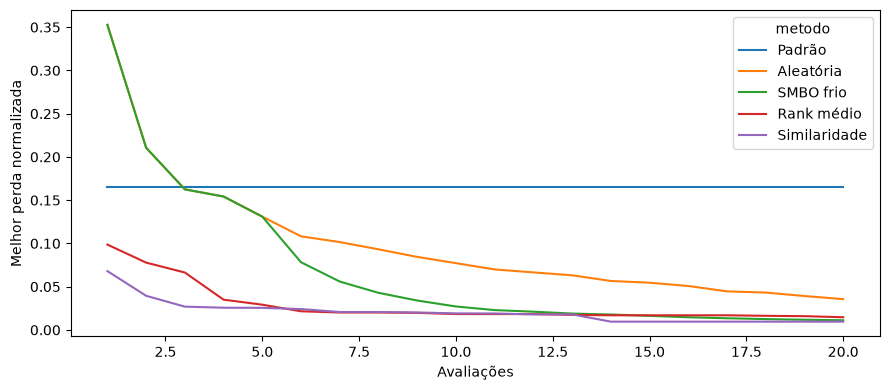

,AUC média
metodo,
similar_estendido_k3,0.020591
rank_medio,0.028757
frio,0.070465
random,0.099965
padrao,0.165195


In [11]:
PRINCIPAIS = ['padrao', 'random', 'frio', 'rank_medio', 'similar_estendido_k3']
ROTULOS = {'padrao':'Padrão', 'random':'Aleatória', 'frio':'SMBO frio', 'rank_medio':'Rank médio', 'similar_estendido_k3':'Similaridade'}
if curvas is not None:
    medias = curvas.groupby(['passo', 'metodo']).perda_normalizada.mean().unstack()
    medias[PRINCIPAIS].rename(columns=ROTULOS).plot(figsize=(9, 4), xlabel='Avaliações', ylabel='Melhor perda normalizada')
    plt.tight_layout()
    plt.savefig(SAIDA / 'curvas.pdf', bbox_inches='tight')
    plt.show()

    auc = curvas.groupby(['dataset', 'seed', 'metodo']).perda_normalizada.mean().rename('auc').reset_index()
    auc_dataset = auc.groupby(['dataset', 'metodo']).auc.mean().unstack()
    display(auc_dataset[PRINCIPAIS].mean().sort_values().rename('AUC média').to_frame())
    auc.to_csv(SAIDA / 'auc.csv', index=False)
else:
    auc_dataset = None
    print('Aguardando os resultados completos.')

Orçamento auc: Friedman=69.581, p=2.782e-14


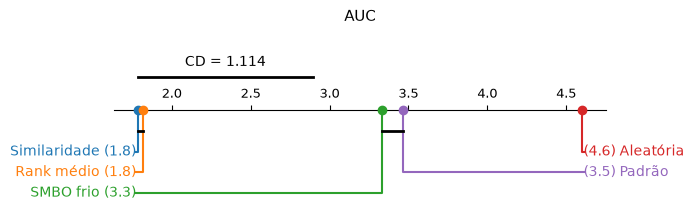

Orçamento 5: Friedman=75.253, p=1.762e-15


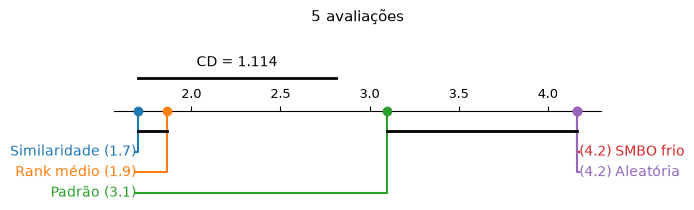

Orçamento 12: Friedman=80.603, p=1.298e-16


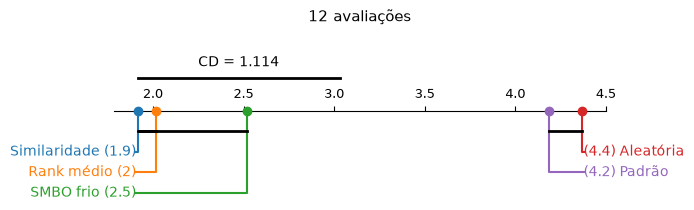

Orçamento 20: Friedman=89.538, p=1.65e-18


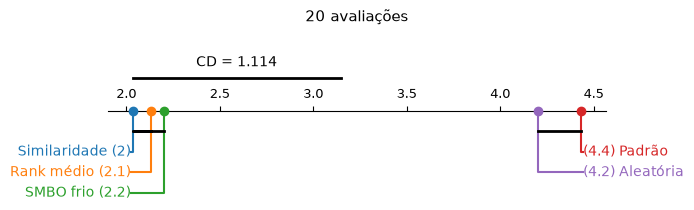

In [12]:
if curvas is not None:
    import scikit_posthocs as sp
    from scipy.stats import studentized_range

    tabelas = {'auc': auc_dataset[PRINCIPAIS]}
    for passo in [N_INIT, 12, T]:
        tabelas[passo] = (curvas[curvas.passo == passo]
            .groupby(['dataset', 'metodo']).perda_normalizada.mean().unstack()[PRINCIPAIS])

    testes = []
    for orcamento, tabela in tabelas.items():
        if (tabela.nunique(axis=1) == 1).all():
            estatistica, p = 0.0, 1.0
        else:
            estatistica, p = friedmanchisquare(*[tabela[c] for c in tabela])
        testes.append(dict(orcamento=str(orcamento), estatistica=float(estatistica), p=float(p)))
        print(f'Orçamento {orcamento}: Friedman={estatistica:.3f}, p={p:.4g}')
        pvalores = sp.posthoc_nemenyi_friedman(tabela.to_numpy())
        pvalores.index = pvalores.columns = tabela.columns
        cd = studentized_range.ppf(0.95, len(tabela.columns), np.inf) / np.sqrt(2) * np.sqrt(len(tabela.columns) * (len(tabela.columns)+1) / (6 * len(tabela)))
        plt.figure(figsize=(7, 2.2))
        sp.critical_difference_diagram(tabela.rename(columns=ROTULOS).rank(axis=1).mean(), pvalores.rename(index=ROTULOS, columns=ROTULOS), label_props={'fontsize':10})
        ax = plt.gca()
        inicio_cd = tabela.rank(axis=1).mean().min()
        ax.plot([inicio_cd, inicio_cd+cd], [1.6, 1.6], color='black', linewidth=2)
        ax.text(inicio_cd+cd/2, 2.0, f'CD = {cd:.3f}', ha='center', va='bottom', fontsize=10)
        ax.set_ylim(top=3.0)
        plt.xticks(fontsize=9)
        plt.title('AUC' if orcamento == 'auc' else f'{orcamento} avaliações', fontsize=11, pad=20)
        plt.tight_layout()
        plt.savefig(SAIDA / f'cd_{orcamento}.pdf', bbox_inches='tight')
        plt.show()
        tabela.to_csv(SAIDA / f'comparacao_{orcamento}.csv')
        pvalores.to_csv(SAIDA / f'nemenyi_{orcamento}.csv')
    pd.DataFrame(testes).to_csv(SAIDA / 'friedman.csv', index=False)
else:
    print('Testes e diagramas aguardam os resultados completos.')

## 10. Análise 2 — a similaridade realmente orienta a escolha?

Compare similaridade com **rank médio**. Se empatarem, não podemos atribuir a vantagem
às meta-características: configurações geralmente boas podem explicar o ganho.

Depois compare **Xbase × Xestendido**, para k=1,3,5. Apresente todas as combinações,
sem escolher apenas a melhor depois de olhar os resultados.

,AUC média
metodo,
similar_base_k5,0.016472
similar_estendido_k1,0.018844
similar_estendido_k3,0.020591
similar_estendido_k5,0.021708
similar_base_k3,0.022584
similar_base_k1,0.023560
rank_medio,0.028757
frio,0.070465


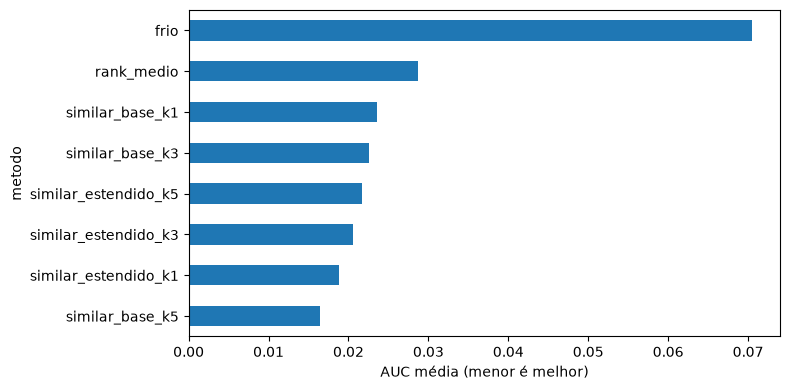

In [13]:
if auc_dataset is not None:
    similares = [c for c in auc_dataset if c.startswith('similar_')]
    resumo = auc_dataset[['frio', 'rank_medio', *similares]].mean().sort_values()
    display(resumo.rename('AUC média').to_frame())
    resumo.plot.barh(figsize=(8, 4), xlabel='AUC média (menor é melhor)')
    plt.tight_layout()
    plt.savefig(SAIDA / 'ablation.pdf', bbox_inches='tight')
    plt.show()
    resumo.to_csv(SAIDA / 'resumo_x_k.csv')
else:
    print('Comparação de X e k pendente.')

## 11. Análise 3 — em quais datasets o warm-start falha?

Para o braço principal, calculamos **ganho = AUC do frio − AUC por similaridade**.
Um ganho negativo significa que o warm-start foi pior.

Relacionamos o ganho com a distância ao vizinho mais próximo. Nos piores casos, olhe
quais eram os vizinhos e as configurações iniciais. A distância é um diagnóstico;
não prova sozinha por que houve uma falha.

,meta,vizinho,distancia,ganho
dataset,,,,
a2,estendido,a7,4.852035,-0.116394
analcatdata_apnea3,estendido,forestFires,5.812924,0.012467
meta,estendido,forestFires,5.058603,0.018685
space_ga,estendido,a2,370.289092,0.025412
compactiv,estendido,cpu_small,1.513676,0.026637
cpu_small,estendido,compactiv,1.525439,0.028247
boston,estendido,abalone,4.906420,0.032630
treasury,estendido,mortgage,0.779467,0.033052
heat,estendido,acceleration,4.913621,0.033095


Spearman distância–ganho: 0.150, p=0.4283


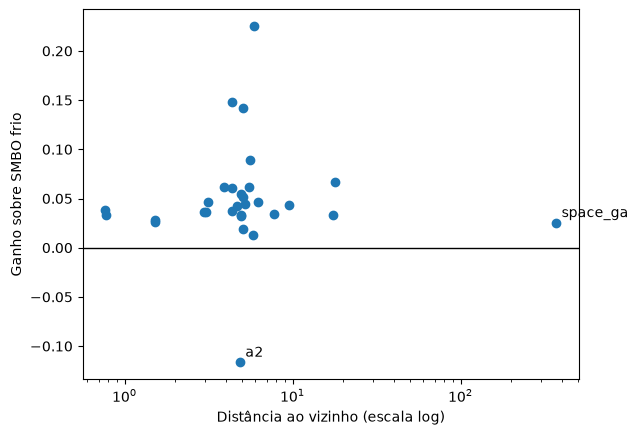

,dataset,vizinhos,iniciais,perda_inicial_normalizada,config_otima,ganho
1,a2,"a7,kdd_coil_1,boston","c030,c050,c010,c031,c000",0.300738,c033,-0.116394
7,analcatdata_apnea3,"forestFires,meta,abalone","c011,c012,c000,c023,c022",0.003925,c040,0.012467
22,meta,"forestFires,analcatdata_apnea3,heat","c011,c040,c023,c050,c021",0.015253,c012,0.018685
26,space_ga,"a2,a7,a3","c033,c030,c023,c010,c002",0.018810,c051,0.025412
12,compactiv,"cpu_small,acceleration,fuel_consumption_country","c040,c030,c020,c010,c050",0.015649,c051,0.026637
14,cpu_small,"compactiv,acceleration,fuel_consumption_country","c051,c030,c020,c040,c010",0.000000,c040,0.028247


In [14]:
if auc_dataset is not None:
    falhas = distancias[distancias.meta == 'estendido'].copy().set_index('dataset')
    falhas['ganho'] = auc_dataset.frio - auc_dataset['similar_estendido_k3']
    display(falhas.sort_values('ganho'))
    if falhas.distancia.nunique() > 1 and falhas.ganho.nunique() > 1:
        rho, p = spearmanr(falhas.distancia, falhas.ganho)
        print(f'Spearman distância–ganho: {rho:.3f}, p={p:.4g}')
    plt.scatter(falhas.distancia, falhas.ganho)
    plt.axhline(0, color='black', linewidth=1)
    plt.xscale('log')
    for nome in ['a2', 'space_ga']:
        ponto = falhas.loc[nome]
        plt.annotate(nome, (ponto.distancia, ponto.ganho), xytext=(4, 4), textcoords='offset points')
    plt.xlabel('Distância ao vizinho (escala log)')
    plt.ylabel('Ganho sobre SMBO frio')
    plt.savefig(SAIDA / 'distancia_ganho.pdf', bbox_inches='tight')
    plt.show()
    falhas.to_csv(SAIDA / 'falhas.csv')
else:
    print('Diagnóstico de falhas pendente.')
if auc_dataset is not None:
    diagnosticos = []
    for alvo in matriz.columns:
        treino = matriz.drop(columns=alvo)
        viz = encontrar_vizinhos(Xestendido, alvo)
        iniciais = iniciais_similares(treino, viz, 3)
        inicial_normalizada = ((matriz.loc[iniciais, alvo].min()-matriz[alvo].min()) /
                              (matriz[alvo].max()-matriz[alvo].min()))
        diagnosticos.append(dict(dataset=alvo, vizinhos=','.join(viz.index[:3]),
                                  iniciais=','.join(iniciais),
                                  perda_inicial_normalizada=inicial_normalizada,
                                  config_otima=matriz[alvo].idxmin(),
                                  ganho=falhas.loc[alvo, 'ganho']))
    diagnosticos = pd.DataFrame(diagnosticos).sort_values('ganho')
    display(diagnosticos.head(6))
    diagnosticos.to_csv(SAIDA / 'diagnosticos.csv', index=False)


## 12. Interpretação dos resultados

O warm-start principal (Xestendido, k=3) reduziu a AUC normalizada de 0,0705 no SMBO frio para 0,0206, uma redução de 70,8% (Nemenyi, p=0,0014). A vantagem foi significativa após cinco avaliações, mas não nos orçamentos 12 e 20. O ganho está concentrado no início da busca.

A comparação com rank médio não foi significativa na AUC nem nos três orçamentos. Assim, os resultados são compatíveis com o benefício de um portfólio de configurações geralmente boas; não isolam uma contribuição adicional das meta-características. Xestendido melhorou a AUC média em k=1 e k=3, mas piorou em k=5. A menor AUC descritiva foi de Xbase/k=5 (0,0165), sem substituir o braço principal definido previamente.

A similaridade principal melhorou a AUC em 29 datasets e piorou em a2. Os maiores ganhos ocorreram em a3, kdd_coil_1 e a7. Em a2, as iniciais transferidas privilegiaram folhas de tamanho 1 ou 2, enquanto o ótimo da grade usou max_features=0,5 e min_samples_leaf=4; ele não foi avaliado pelo warm-start em vinte passos. A distância ao vizinho mais próximo não apresentou associação significativa com o ganho (Spearman rho=0,150; p=0,428).

Para a pesquisa em seleção dinâmica de modelos para regressão desbalanceada, o resultado recomenda manter um controle por portfólio e verificar se descritores por grupo predizem diferenças de desempenho, além de descreverem os dados. O efeito observado nesta busca de um regressor fixo não estabelece o efeito das mesmas medidas sobre competência local ou seleção dinâmica.


O ótimo é o **melhor entre as 60 configurações**, não de todo o espaço possível. As curvas usam perdas de validação da tabela e não estimam de forma independente a generalização do modelo selecionado. Xestendido acrescenta medidas de todos os grupos e razões redundantes; seu efeito não isola o papel dos raros. As comparações das seis variantes de X/k são descritivas. As sementes são agregadas por dataset antes dos testes, e ausência de significância não demonstra equivalência.

**Referências que orientam o experimento:**

- Juscimara Avelino, George Cavalcanti e Rafael Cruz (2025). [Meta-IR: Imbalanced Regression Pipeline Recommendation](https://arxiv.org/html/2507.11901v1).
- Avelino, Cavalcanti e Cruz (2024). [Resampling strategies for imbalanced regression](https://link.springer.com/article/10.1007/s10462-024-10724-3).
- Feurer, Springenberg e Hutter (2014/2015). [Inicialização de otimização por meta-learning](https://ojs.aaai.org/index.php/AAAI/article/view/9354).
- Probst, Wright e Boulesteix (2019). [Hiperparâmetros de Random Forest](https://arxiv.org/abs/1804.03515).

## 13. Conferência dos resultados
Verificamos a matriz, os folds, as trajetórias e a reprodução do padrão anterior.

In [15]:
# Conferência dos artefatos experimentais.
perdas_check = pd.read_csv(SAIDA / 'perdas_por_fold.csv')
assert len(perdas_check) == 60 * 30 * 10
assert not perdas_check.duplicated(['dataset', 'config', 'fold']).any()
assert perdas_check.groupby(['dataset', 'config']).size().eq(10).all()
assert np.isfinite(perdas_check.sera).all()
np.testing.assert_allclose(
    perdas_check.pivot_table(index='config', columns='dataset', values='sera').loc[IDS, DATASETS],
    matriz, rtol=1e-12)
np.testing.assert_allclose(matriz.loc['c000'], P_anterior.loc[DATASETS, 'RF'], rtol=1e-12)
assert curvas.shape[0] == 30 * N_SEMENTES * 10 * T
assert curvas.groupby(['dataset', 'seed', 'metodo']).size().eq(T).all()
for (alvo, seed, metodo), grupo in curvas.groupby(['dataset', 'seed', 'metodo']):
    grupo = grupo.sort_values('passo')
    assert grupo.passo.tolist() == list(range(1, T+1))
    if metodo != 'padrao':
        assert grupo.config.nunique() == T
    esperada = np.minimum.accumulate(matriz.loc[grupo.config, alvo].to_numpy())
    np.testing.assert_allclose(grupo.melhor, esperada, rtol=1e-12)
assert curvas.perda_normalizada.between(-1e-12, 1+1e-12).all()
print('Conferência concluída: 18.000 perdas por fold; matriz 60×30; 120.000 pontos de curvas; sem repetição nas buscas; padrão reproduzido nos 30 datasets.')
(SAIDA / 'validacao.json').write_text(json.dumps(dict(
    ajustes=18000, matriz=[60,30], pontos_curvas=len(curvas),
    configuracoes_distintas_por_busca=T, padrao_reproduzido_30_datasets=True), indent=2))


Conferência concluída: 18.000 perdas por fold; matriz 60×30; 120.000 pontos de curvas; sem repetição nas buscas; padrão reproduzido nos 30 datasets.


168